In [1]:
# Librerias
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# DCCoches Robados

La idea de la actividad es resolver un problema de clasificación binaria, específicamente determinar si un vehículo terminará en estado
*SEBV ENCONTRO* o *SEBV BUSCA*.

## 3.3.1. Análisis exploratorio de Datos

In [2]:
# 1. Cargamos los datos y comentamos algunos aspectos

# Pal colab:
#df = pd.read_csv('datos_coches.csv', on_bad_lines='skip')

# Pal VSCode:
df = pd.read_csv(r'Datos Tarea 2\datos_coches.csv', on_bad_lines='skip')
df.head()

,id_prose,sin_patente,sin_fecha_siniestro,ase_abreviatura,obs_ult_estado,sin_siniestro,sin_fecha_denuncia,lug_desc,pro_descripcion_provincia,reg_descripcion_comuna,...,sin_valor_comercial_veh,sin_dispositivos_vehiculo,reg_descripcion_region_asegurado,reg_descripcion_comuna_asegurado,reg_descripcion_region_conductor,sin_comisaria,sin_fecha_parte,sin_relato,sin_activo,EncontradoOtraVia
0,75851.0,DGLP26,17-11-2015 0:00,LIBERTY,NaN,1405392.0,19-11-2015 0:00,Otra,Otra,Otra,...,7266584.0,N,Región del Biobío,Concepción,Otra,Subcomisaría San Pedro,01-01-1900 0:00,EL VEHÍCULO LO HABÍA FACILITADO Y EL DÍA MARTE...,S,SI
1,79450.0,GHXW96,15-04-2016 0:00,LIBERTY,NaN,1432788.0,19-04-2016 0:00,Otra,Otra,Otra,...,15834980.0,N,Región Metropolitana de Santiago,Pudahuel,Otra,27a Comisaría Aeropuerto Internacional Prefect...,15-04-2016 0:00,EL DÍA 15 DE ABRIL SE DEJA VEHÍCULO EN DIRECC...,S,NO
2,54231.0,FZHZ87,05-10-2013 0:00,LIBERTY,NaN,1247605.0,08-10-2013 0:00,Otra,Otra,Otra,...,10402278.0,N,Región Metropolitana de Santiago,Huechuraba,Otra,47a Comisaría Los Domínicos Prefectura Santiag...,05-10-2013 0:00,Estaba en la casa de mi polola deje estacionad...,S,SI
3,79396.0,HVDP13,03-03-2016 0:00,LIBERTY,NaN,1430252.0,04-03-2016 0:00,Otra,Otra,Otra,...,7719201.0,N,Región Metropolitana de Santiago,Ñuñoa,Otra,44a Comisaría Lo Prado Prefectura Santiago Occ...,03-03-2016 0:00,Deje estacionado el vehículo en la dirección i...,S,NO
4,46014.0,WK7220,03-09-2012 0:00,LIBERTY,NaN,1176541.0,03-09-2012 0:00,Otra,Otra,Otra,...,6767844.0,N,Región del Maule,Parral,Otra,Tenencia Longaví,03-09-2012 0:00,DEJE EL VEH ESTACIONADO EN UN PREVIO Y HOY EN...,S,NO


In [3]:
print(f"Hay {df.shape[0]} filas y {df.shape[1]} columnas")
print(f"\nHay {df.isna().sum().sum()} valores nulos")
print(f"\n{df.value_counts()}")

Hay 7133 filas y 29 columnas

Hay 6841 valores nulos

id_prose  sin_patente  sin_fecha_siniestro  ase_abreviatura  obs_ult_estado                                                                                        sin_siniestro  sin_fecha_denuncia  lug_desc   pro_descripcion_provincia  reg_descripcion_comuna  sin_hora_siniestro  esp_desc        sin_check_registro_civil  sin_concurrencia  sin_ind_caso_raro  tve_desc       mar_desc    sin_ano_vechiculo  cve_desc  sin_valor_comercial_veh  sin_dispositivos_vehiculo  reg_descripcion_region_asegurado  reg_descripcion_comuna_asegurado  reg_descripcion_region_conductor  sin_comisaria                                       sin_fecha_parte  sin_relato                                                                                                                                                                                                                                                                                                          

Podemos apreciar un dataframe bastante extenso, cuenta con un total de **206.857** datos distribuidos en 7133 filas y 29 columnas. Hay mucha información sobre los siniestros, cada uno con su propio id, además se indica la patente del vehículo robado, observaciones del estado del automovil, fecha de la denuncia, lugar donde se efectuó el siniestro, hora del siniestro, etc. Estos atributos son tanto strings (por ejemplo el relato del siniestro) como floats/ints (valor del vehículo). La variable a predecir es **esp_desc** que es el estado de búsqueda SEBV.

Analicemos a profundidad los datos y su relación con la variable objetivo:

In [4]:
df['esp_desc']

0           SEBV BUSCA
1           SEBV BUSCA
2           SEBV BUSCA
3           SEBV BUSCA
4           SEBV BUSCA
             ...      
7128    SEBV ENCONTRO 
7129    SEBV ENCONTRO 
7130    SEBV ENCONTRO 
7131    SEBV ENCONTRO 
7132    SEBV ENCONTRO 
Name: esp_desc, Length: 7133, dtype: object

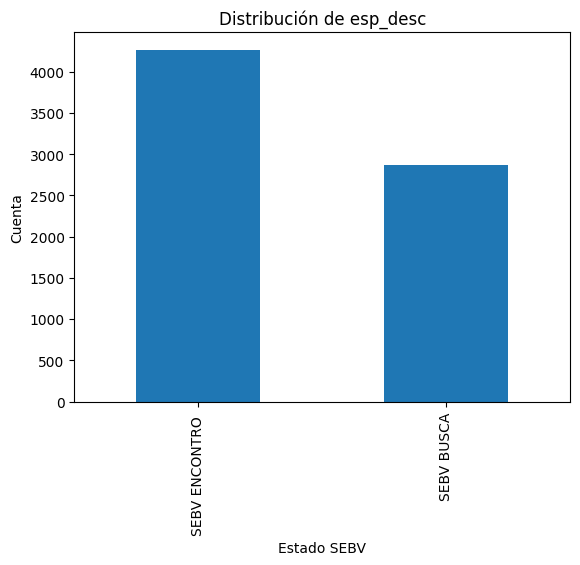

In [5]:
#Vamos a graficar los resultados de nuestro dato para ver su distribución:
ocurrencias = df['esp_desc'].value_counts().plot(kind='bar')

plt.title('Distribución de esp_desc')
plt.xlabel('Estado SEBV')
plt.ylabel('Cuenta')
plt.show()

Referencia:
Ben. (1 de marzo de 2018). Pandas plot value_counts barplot in descending manner [Comentario en un foro en línea]. Stack Overflow. https://stackoverflow.com/questions/49059956/pandas-plot-value-counts-barplot-in-descending-manner

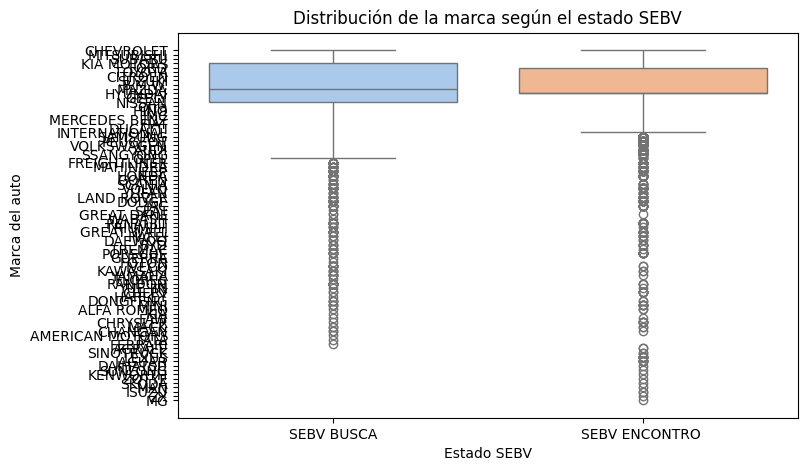

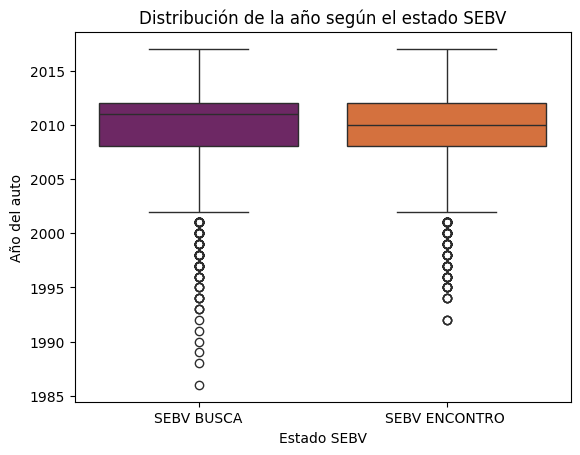

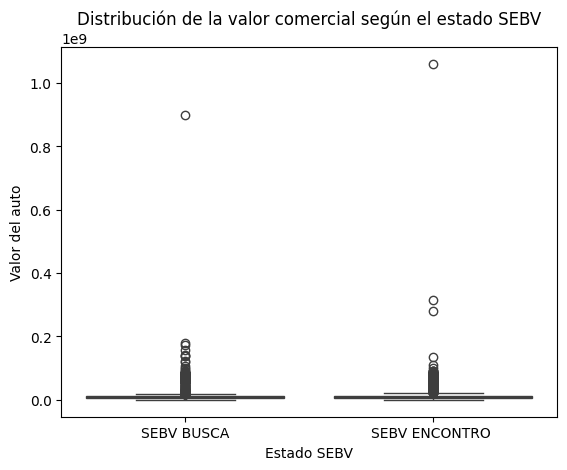

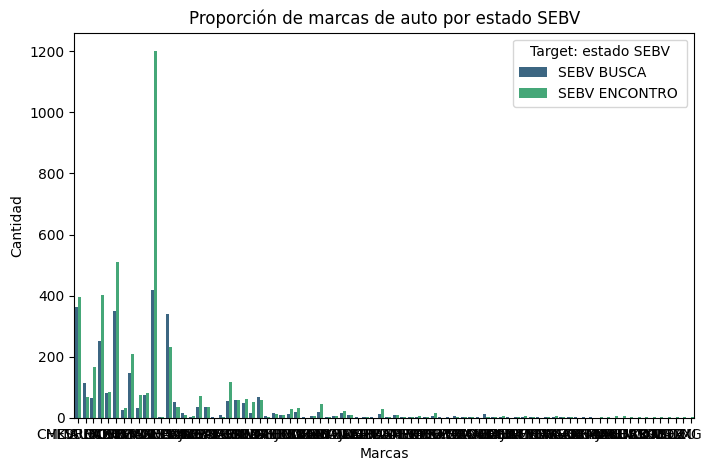

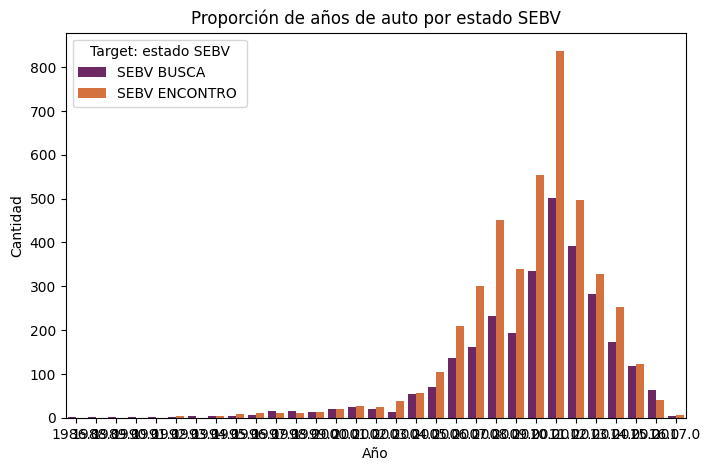

In [6]:
# Para ver como se relaciona una feature con la variable objetivo hacemos boxplots
plt.figure(figsize=(8, 5))
# Marca del vehículo:
sns.boxplot(x='esp_desc', y='mar_desc', data=df, palette='pastel', hue='esp_desc')
plt.title('Distribución de la marca según el estado SEBV')
plt.xlabel('Estado SEBV')
plt.ylabel('Marca del auto')
plt.show()

# Año del vehículo:
sns.boxplot(x='esp_desc', y='sin_ano_vechiculo', data=df, palette='inferno', hue='esp_desc')
plt.title('Distribución de la año según el estado SEBV')
plt.xlabel('Estado SEBV')
plt.ylabel('Año del auto')
plt.show()

# Valor del vehículo:
sns.boxplot(x='esp_desc', y='sin_valor_comercial_veh', data=df, palette='mako', hue='esp_desc' )
plt.title('Distribución de la valor comercial según el estado SEBV')
plt.xlabel('Estado SEBV')
plt.ylabel('Valor del auto')
plt.show()

# Usamos el countplot para graficar la proporción frente a nuestro objetivo
plt.figure(figsize=(8, 5))
sns.countplot(x='mar_desc', hue='esp_desc', data=df, palette='viridis')
plt.title('Proporción de marcas de auto por estado SEBV')
plt.xlabel('Marcas')
plt.ylabel('Cantidad')
plt.legend(title='Target: estado SEBV')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x='sin_ano_vechiculo', hue='esp_desc', data=df, palette='inferno')
plt.title('Proporción de años de auto por estado SEBV')
plt.xlabel('Año')
plt.ylabel('Cantidad')
plt.legend(title='Target: estado SEBV')
plt.show()

Referencia:
Seaborn. (s.f.). Visualizing categorical data. https://seaborn.pydata.org/tutorial/categorical.html


De los gráficos anteriores primero identificamos que la distribución de los datos de nuestra variable objetivo está cargada hacia la categoría de SEBV ENCONTRO, luego nuestros modelos de categorización y predicción pueden resultar sesgados a este valor.

Después, viendo la relación entre features y la variable objetivo, grafiqué algunas que me parecieron relevantes. Aunque todas las features presentan un alto grado de asimetría, la variable de valor comercial del auto presenta una asimetría altísima, casi no se ven las cajas del boxplot en los datos por un par de outliers en nuestros datos. Igualmente todas las características graficadas presentan asimetría y varios valores no pueden ser contenidos en los boxplots. Tendremos que ver más a detalle si estos outliers corresponden a errores de las personas que introdujeron los datos o si son por ejemplo autos de lujo que se escapan enormemente de la media.

Finalmente los útlimos dos gráficos nos sirven para ver la proporción de features categóricas con respecto a nuestra variable a predecir (que también es categórica). De estos podemos ver que existe una moda bien marcada para la marca y el año de los vehículos que sufren siniestros. A simple vista también en casi todas las categorías de año y de marcas se observan más observaciones de la categoría SEBV ENCONTRO que de SEBV BUSCA.

## 3.3.2. Procesamiento de datos

El pipeline para procesar y limpiar el dataset va a ser primero eliminar las filas duplicadas con el **id_prose**, esta columna luego también será dropeada ya que no aporta información útil para la predicción. En general las columnas de identificación: **id_prose, sin_patente, sin_siniestro**, no aportan información para la construcción del modelo, si es que llegan a presentar una relación con la categoría a predecir esta va a ser una coincidencia, en la vida real el número con el cual termina tu patente no incide en si van a encontrar tu auto luego de que te lo roben. QUe el modelo tenga estos datos podría causar *overfitting*, por lo que es mejor eliminarlas. Al final del procesamiento de datos tambitambién se va a dropear la columna de **sin_relato** ya que encuentro complicado extraer información de forma confiable de texto libre, sin embargo la podemos utilizar entremedio.

Veamos otras columnas:

In [7]:
df.drop_duplicates(subset='id_prose', inplace=True)
df.drop_duplicates(subset='sin_siniestro', inplace=True)
df = df.drop(columns=['id_prose', 'sin_siniestro', 'sin_patente'])
df.shape

(7133, 26)

In [8]:
# Veamos si podemos reemplazar algunas columnas por otras
print(df['reg_descripcion_comuna'].value_counts())
print(df['pro_descripcion_provincia'].value_counts())
print(df['reg_descripcion_region_conductor'].value_counts())


reg_descripcion_comuna
Otra                   6774
Santiago                 96
Providencia              45
Las Condes               32
Vitacura                 23
Ñuñoa                    21
Lo Barnechea             14
Maipú                    13
La Florida                9
Antofagasta               9
San Miguel                9
Recoleta                  7
Concepción                6
Huechuraba                6
Calama                    5
Quinta Normal             5
Peñalolén                 5
La Reina                  4
Estación Central          3
Macul                     3
El Bosque                 3
Copiapó                   3
Pedro Aguirre Cerda       3
Pudahuel                  3
San Bernardo              3
Coquimbo                  3
La Serena                 3
Renca                     2
Iquique                   2
La Pintana                2
Los Ángeles               2
La Cisterna               2
San Joaquín               1
Puente Alto               1
Lo Espejo                

In [9]:
# Veamos el porcentaje de valores que son 'Otra' (ruido)
print(f"Otra en reg_descripcion_comuna: {(df['reg_descripcion_comuna'] == 'Otra').sum() / df.shape[0]}")
print(f"Otra en pro_descripcion_provincia: {(df['pro_descripcion_provincia'] == 'Otra').sum() / df.shape[0]}")
print(f"Otra en reg_descripcion_region_conductor: {(df['reg_descripcion_region_conductor'] == 'Otra').sum() / df.shape[0]}")

# 95% de los datos en estas columnas son ruido para nuestro modelo


Otra en reg_descripcion_comuna: 0.9496705453525865
Otra en pro_descripcion_provincia: 0.9495303518856021
Otra en reg_descripcion_region_conductor: 0.9746249824758166


In [10]:
# Estas últimas columnas no nos entregan mucha más información que las otras
df = df.drop(columns=['reg_descripcion_comuna', 'pro_descripcion_provincia',
                       'reg_descripcion_region_conductor'])

# En cambio veamos las otras columnas de region/comuna y además una extra:
print('------------')
print(f"Únicos en descripcion_reg_as: {df['reg_descripcion_region_asegurado'].nunique()}")
print(f"Únicos en descripcion_com_as: {df['reg_descripcion_comuna_asegurado'].nunique()}")
print(f"Únicos en comisaria: {df['sin_comisaria'].nunique()}")

------------
Únicos en descripcion_reg_as: 13
Únicos en descripcion_com_as: 87
Únicos en comisaria: 885


In [11]:
# Dejamos la descripción de la región asegurado, ya que tiene menor cardinalidad
# que la de comuna, además de que ya cubre estos datos, por cardinalidad también dropeamos
# la comisaría
df = df.drop(columns=['reg_descripcion_comuna_asegurado', 'sin_comisaria'])

Por inspección notamos que existen tres columnas que nos entregan información de la fecha del siniestro: **sin_fecha_siniestro**, **sin_fecha_denuncia** y **sin_fecha_parte**. Tenemos que extraer la información del dataframe y transformar el string de la fecha al formato dia-mes-año. También se nos proporciona una hora en estas columnas pero por inspección se ve que todas son 0:00, además hay otra columna que registra la hora del siniestro por lo que no necesitamos procesar esa parte de nuestros datos. Utilizamos pandas que tiene integrado funciones para manejar series de tiempo.

Mucho del código se modificó de la documentación:

Pandas. (s.f.). Time series / date functionality. https://pandas.pydata.org/docs/user_guide/timeseries.html

Pandas- (s.f). pandas.to_datetime- https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html

In [12]:
# Convirtamos las fechas de las columnas
col_fechas = ['sin_fecha_siniestro', 'sin_fecha_denuncia', 'sin_fecha_parte']
for col in col_fechas:
  df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')

# Extraemos el dia, mes, año. En este orden, por eso antes hicimos
# dayfirst=True
df['sin_year'] = df['sin_fecha_siniestro'].dt.year
df['sin_mes'] = df['sin_fecha_siniestro'].dt.month
df['sin_dia_semana'] = df['sin_fecha_siniestro'].dt.dayofweek # 0 es lunes
df['sin_finde'] = (df['sin_dia_semana'] >= 5).astype(int)

# Días entre siniestro y denuncia. Al final nos interesa ver cuantos
# días pasaron entremedio, no cuando fue la denuncia y el siniestro
# por separado:
df['dias_hasta_denuncia'] = (
    df['sin_fecha_denuncia'] - df['sin_fecha_siniestro']).dt.days.clip(lower=0)
df['dias_hasta_denuncia']

# Eliminamos las otras columnas, nos quedamos con si es finde o no
df.drop(columns=['sin_year', 'sin_mes', 'sin_dia_semana'], inplace=True)

Con estos datos extraemos las fechas y contamos los días desde el sinistro hasta el día de la denuncaia, la función .dt.days considera los cambios de mes y año, luego un siniestro que ocurre el día 30 de enero y es denunciado el día 1 de febrero lo marca como 2 días y no como 1 - 30 = -29. El clip también se encarga de las fechas mal inputadas (si se hace la denuncia antes de que ocurra el siniestro), acá les ponemos que han pasado 0 días.

Veamos la columna de la fecha del parte:

In [13]:
#df['sin_fecha_parte'] -> Notamos que hay una fecha muy peculiar
print(df['sin_fecha_parte'].value_counts()) # Hay 311 partes emitidos el 1/1/1900

df.query("sin_fecha_parte == '1900-01-01'")[['sin_fecha_siniestro', 'sin_fecha_parte']]

sin_fecha_parte
1900-01-01    311
2013-10-01     14
2013-12-27     13
2012-07-11     13
2015-05-09     12
             ... 
2011-08-29      1
2014-05-25      1
2013-11-24      1
2011-08-24      1
2014-04-23      1
Name: count, Length: 1918, dtype: int64


C:\Users\Rafal\AppData\Local\Temp\ipykernel_43752\4004963836.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df.query("sin_fecha_parte == '1900-01-01'")[['sin_fecha_siniestro', 'sin_fecha_parte']]


,sin_fecha_siniestro,sin_fecha_parte
0,2015-11-17,1900-01-01
9,2012-03-27,1900-01-01
47,2014-03-30,1900-01-01
81,2012-10-04,1900-01-01
91,2011-11-10,1900-01-01
...,...,...
7013,2015-02-19,1900-01-01
7085,2011-05-24,1900-01-01
7092,2015-12-31,1900-01-01
7100,2012-08-16,1900-01-01


Podemos notar que no hay una buena inputación del dato de la fecha del parte, ya que hay muchos con la fecha 01/01/1900, cosa que contradice que los siniestros hayan ocurrido después del año 2000. Luego procesamos estas columnas y nos quedamos con el dato de que si tienen parte en el día correcto o no, se hará el siguiente mapeo:

* año != 1900 = True -> 1
* año != 1900 = False -> 0


In [14]:
df['tiene_fecha_parte'] = (df['sin_fecha_parte'].dt.year != 1900).astype(int)

#Eliminamos las columnas con fechas
df.drop(columns=['sin_fecha_siniestro', 'sin_fecha_denuncia',
                 'sin_fecha_parte'], inplace=True)

In [15]:
#Ahora transformemos las horas del formato 08:00:00 AM -> categoría

# Creamos una función que toma la hora de la columna
def hora(hr_str):
  try:
    from datetime import datetime
    hr = datetime.strptime(hr_str, '%I:%M:%S %p') # [1] Uso de IA
    return hr
  except:
    return np.nan

df['sin_hora'] = df['sin_hora_siniestro'].apply(hora)

# Hacemos las categorías dependiendo de la hora
bins = [-1, 11, 17, 23]
labels = [0, 1, 2] # 0=mañana, 1=tarde, 2=noche

df['sin_hora_cat'] = pd.cut(
    df['sin_hora'].dt.hour, bins=bins, labels=labels).astype(float)

# Dropeamos las columnas procesadas
df.drop(columns=['sin_hora_siniestro', 'sin_hora'], inplace=True)

Referencia:
DigitalOcean. (10 de agosto de 2022). Pandas DataFrame apply() examples. https://www.digitalocean.com/community/tutorials/pandas-dataframe-apply-examples

[1] La linea me la autocompletó gemini.

In [16]:
# Veamos que columnas tienen NaN values
print(df.columns[df.isna().any()])

print(f"NaN values en obs_ult_estado: {df['obs_ult_estado'].isna().sum()}")
# Casi un 96% de los datos de esta columna son NaN, por lo que la podemos eliminar
df = df.drop(columns=['obs_ult_estado'])

Index(['obs_ult_estado'], dtype='object')
NaN values en obs_ult_estado: 6841


In [17]:
# Trabajemos las columnas "binarias"
binarias = ['sin_check_registro_civil', 'sin_concurrencia', 'sin_ind_caso_raro',
            'sin_dispositivos_vehiculo']
mapeo_binarias = {'N': 0, 'S': 1}

for bin in binarias:
  df[bin] = df[bin].replace(mapeo_binarias)

df['EncontradoOtraVia'] = df['EncontradoOtraVia'].map({'SI': 1, 'NO': 0})

df

C:\Users\Rafal\AppData\Local\Temp\ipykernel_43752\3074542086.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[bin] = df[bin].replace(mapeo_binarias)


,ase_abreviatura,lug_desc,esp_desc,sin_check_registro_civil,sin_concurrencia,sin_ind_caso_raro,tve_desc,mar_desc,sin_ano_vechiculo,cve_desc,sin_valor_comercial_veh,sin_dispositivos_vehiculo,reg_descripcion_region_asegurado,sin_relato,sin_activo,EncontradoOtraVia,sin_finde,dias_hasta_denuncia,tiene_fecha_parte,sin_hora_cat
0,LIBERTY,Otra,SEBV BUSCA,1,0,0,AUTOMOVIL,CHEVROLET,2011.0,Blanco,7266584.0,0,Región del Biobío,EL VEHÍCULO LO HABÍA FACILITADO Y EL DÍA MARTE...,S,1,0,2,0,0.0
1,LIBERTY,Otra,SEBV BUSCA,1,0,0,CAMIONETA,MITSUBISHI,2014.0,Gris,15834980.0,0,Región Metropolitana de Santiago,EL DÍA 15 DE ABRIL SE DEJA VEHÍCULO EN DIRECC...,S,0,0,4,1,0.0
2,LIBERTY,Otra,SEBV BUSCA,1,0,0,AUTOMOVIL,SUBARU,2014.0,Plateado,10402278.0,0,Región Metropolitana de Santiago,Estaba en la casa de mi polola deje estacionad...,S,1,1,3,1,0.0
3,LIBERTY,Otra,SEBV BUSCA,1,0,0,CAMIONETA,KIA MOTORS,2016.0,Blanco,7719201.0,0,Región Metropolitana de Santiago,Deje estacionado el vehículo en la dirección i...,S,0,0,1,1,1.0
4,LIBERTY,Otra,SEBV BUSCA,1,0,0,CAMIONES,FORD,2007.0,Blanco,6767844.0,0,Región del Maule,DEJE EL VEH ESTACIONADO EN UN PREVIO Y HOY EN...,S,0,0,0,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7128,BCI,Domicilio,SEBV ENCONTRO,1,0,0,STATION WAGON,TOYOTA,2013.0,Blanco,79940385.0,0,Otra,ESTACIONE EL VEHICULO AFUERA LUEGO LLEGARON UN...,S,1,0,1,1,2.0
7129,LIBERTY,Otra,SEBV ENCONTRO,1,0,0,FURGON,HYUNDAI,2008.0,Blanco,6811601.0,0,Región Metropolitana de Santiago,QUEDO EL VEHICULO ESTACIONADO Y AL REGRESAR A ...,S,1,1,1,0,0.0
7130,LIBERTY,Otra,SEBV ENCONTRO,1,0,0,CAMIONETA,TOYOTA,2005.0,Verde,3770005.0,0,Región del Libertador Gral. Bernardo O’Higgins,DEJE VEHÍCULO ESTACIONADO EN LUGAR MENCIONAD Y...,S,0,0,9,1,0.0
7131,BCI,Domicilio,SEBV ENCONTRO,1,0,0,CAMIONETA,Otra,2013.0,Blanco,6642426.0,0,Otra,SINIESTRO DENUNCIADO VIA WEB ...,S,0,0,0,1,2.0


Hacemos este mapeo para las variables binarias:


*   No (N) -> 0
*   Si (S) -> 1

Esto lo hacemos con el fin de que nuestro modelo entienda el vector de características que se le está dando. Hay otra variable binaria pero es un caso especial, veamos que ocurre:

In [18]:
print(df['sin_activo'].value_counts())
# Solamente tiene S en toda la columna! No entrega información
df = df.drop(columns=['sin_activo'])

sin_activo
S    7133
Name: count, dtype: int64


Hay otra columna importante a la cual le vamos a hacer label encoding, nuestra variable objetivo. Hacemos el siguiente mapeo:

* SEBV ENCONTRO -> 1
* SEBV BUSCA -> 0

In [19]:
print(df['esp_desc'].unique()[:10]) # SEBV ENCONTRO

# Le cambio el nombre también porque se me olvida
df['target'] = df['esp_desc'].map({'SEBV ENCONTRO ': 1, 'SEBV BUSCA': 0})
df = df.drop(columns=['esp_desc'])

df['target'].value_counts()

['SEBV BUSCA' 'SEBV ENCONTRO ']


target
1    4269
0    2864
Name: count, dtype: int64

Antes de seguir con otras features, voy a escalar el valor comercial del vehículo ya que como vimos en el gráfico en la parte anterior eran números muy grandes, si los dividimos en un millpon, se vuelven manejables:

In [20]:
df['sin_valor_comercial_veh'] = df['sin_valor_comercial_veh'] / 1000000

Sigamos con las variables categóricas, vamos a separar nuestras variables dependiendo si hacemos One-Hot Encoding, Label Encoding u otros.

Lo que hace el label encoding es asignar un número a cada categoría distinta dentro de una columna, se usa cuando existe un órden en la variable o simplemente hay muchas categorías únicas.

Por otro lado One-Hot sirve cuando no hay una ordinalidad en los datos, denota la presencia o ausencia de una cierta categoría.

Finalmente también vamos a encodear alguna columna por su frecuencia (las marcas de auto).

Referencias:
GeeksforGeeks. (14 de junio de 2024). ML | One Hot Encoding. https://www.geeksforgeeks.org/ml-one-hot-encoding/

GeeksforGeeks. (2 de julio de 2024). ML | Label Encoding of Datasets in Python. https://www.geeksforgeeks.org/ml-label-encoding-of-datasets-in-python/

Arévalo F, Samsó J. (16 de marzo 2026). *Ayudantía 1: Intro a ML, uso de pandas, numpy, y sklearn*. Archivo .ipynb. Recuperado de Canvas uc.

In [21]:
df = df.copy()

# Vemos columnas para los encodings:
print(f"\nAseguradoras: {df['ase_abreviatura'].nunique()}") # 5 aseguradoras
print(f"\nRegiones: {df['reg_descripcion_region_asegurado'].nunique()}") # 13 regiones
print(f"\nNúmero de lugares: {df['lug_desc'].nunique()}") # 5 Lugares
print(f"\nTipos de vehículo: {df['tve_desc'].nunique()}") # 15 tipos
print(f"\nColores únicos: {df['cve_desc'].nunique()}") # 15 colores



Aseguradoras: 5

Regiones: 13

Número de lugares: 5

Tipos de vehículo: 15

Colores únicos: 15


In [22]:
# Label Encoding
le = LabelEncoder()
label_cols = ['ase_abreviatura', 'reg_descripcion_region_asegurado']
for col in label_cols:
  df[col] = le.fit_transform(df[col])

In [23]:
# One-Hot Encoding

ohe_cols = ['lug_desc', 'tve_desc', 'cve_desc']
# El drop first hace que borremos una categoría, esto no afecta al modelo
# ya que se evita la dummy variable trap
df = pd.get_dummies(df, columns=ohe_cols, prefix=ohe_cols, drop_first=True)

Referencia:
https://www.geeksforgeeks.org/machine-learning/ml-dummy-variable-trap-in-regression-models/

In [24]:
# Para la marca del auto, mapeamos la marca a su frecuencia
frec_map = df['mar_desc'].value_counts()
df['mar_freq'] = df['mar_desc'].map(frec_map)
df.drop(columns=['mar_desc'], inplace=True)

In [25]:
# Al final dropeamos el relato del siniestro
df = df.drop(columns=['sin_relato'])
print(f"\nShape final del dataset limpio: {df.shape}")


Shape final del dataset limpio: (7133, 47)


In [26]:
print(df.columns)

Index(['ase_abreviatura', 'sin_check_registro_civil', 'sin_concurrencia',
       'sin_ind_caso_raro', 'sin_ano_vechiculo', 'sin_valor_comercial_veh',
       'sin_dispositivos_vehiculo', 'reg_descripcion_region_asegurado',
       'EncontradoOtraVia', 'sin_finde', 'dias_hasta_denuncia',
       'tiene_fecha_parte', 'sin_hora_cat', 'target',
       'lug_desc_Centro Comercial', 'lug_desc_Colegio', 'lug_desc_Domicilio',
       'lug_desc_Otra', 'tve_desc_BUSES Y TAXIBUSES', 'tve_desc_Bicicleta',
       'tve_desc_CAMIONES', 'tve_desc_CAMIONETA',
       'tve_desc_CARROS DE ARRASTRE',
       'tve_desc_ESTANQUES METALICOS DE ACERO INOXIDABLE (SIN CHASSIS)',
       'tve_desc_FURGON', 'tve_desc_MINIBUS', 'tve_desc_MOTOCICLETAS',
       'tve_desc_Otro', 'tve_desc_REMOLQUES (CARROCERIA PLANA)',
       'tve_desc_SEMIREMOLQUES (CARROCERIA PLANA)', 'tve_desc_STATION WAGON',
       'tve_desc_TODO TERRENO', 'cve_desc_Azul', 'cve_desc_Beige',
       'cve_desc_Blanco', 'cve_desc_Café', 'cve_desc_Celeste',
 

## 3.3.3. División de Datos

Al igual que nuestro modelo anterior (DCCasa),  se optará por un modelo de 80-10-10. Claramente con menos de 10.000 entradas, es importante que el número de datos de entrenamiento sea suficiente para obtener buenos resultados, pero también no queremos que su varianza sea muy alta. Con este split quedan aproximadamente 5700 entradas para entrenamiento y 700 para tanto validación como testeo. También vamos a estratificar la muestra para obtener buenos resultados, manteniendo la proporción de las clases SEBV BUSCA y SEBV ENCONTRO (recordemos que estaban cargados a los encontrados).


In [27]:
# Primero separemos las columnas: features 'X' y target 'y'
X = df.drop(columns=['target'])
y = df['target']

# Separamos 80-20
train, temp = train_test_split(df, test_size=0.2, random_state=42, stratify=y)
# Separamos el 20: 10-10
val, test = train_test_split(temp, test_size=0.5, random_state=42, stratify=temp['target'])

# Set de Entrenamiento
X_train = train.drop(columns=['target'])
y_train = train['target']
# Set de Validación
X_val = val.drop(columns=['target'])
y_val = val['target']
# Set de Prueba
X_test = test.drop(columns=['target'])
y_test = test['target']

Antes de entrenar y explicar SVM, es necesario escalar los valores de nuestra matriz de características, lo hacemos con StandardScaler de scikitlearn. Lo que ocurre con SVM es que si tenemos datos binarios y otros con valores muy grandes (como pueden ser los de *sin_valor_comercial_veh*) el modelo pensará que la columna con los mayores valores es más importante, ya que lo que hace es encontrar un hiperplano que separa las clases maximizando la distancia.

Referencia:
Scikit-learn. (s.f.). sklearn.preprocessing.StandardScaler. Recuperado el 24 de mayo de 2024, de https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler = StandardScaler().set_output(transform="pandas")
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

Ahora sí podemos usar GridSearch (recomendado por el enunciado), considero que uno al tener el poder de decisión al poder elegir que parámetros probar para luego seleccionar los mejores es mejor que dejarlo al azar. Además para grillas pequeñas, GridSearch es mucho más preciso para encontrar los hiperparámetros, si tuviera mucha importancia probar distintos hiperparámetros, dando como resultado una grilla muy grande, se prefiere RandomizedSearch.

Fe de erratas: Llevaba muchísimo tiempo corriendo así que no usaré grid search y voy a utilizar los fors anidados nuevamente para el DecisionTree, creo que hacer cross-validation hace que sea muy pesado correr este comando acá. También voy a implementar RandomSearchCV ya que el dataset es muy grande, por lo que Randomized Search debería ser más rápido

In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score # [2] Uso de IA

# Decision Tree
param_grid_dt = {
    'max_depth': [3, 5, 7, 9],
    'min_samples_split': [10, 20, 50],
    'min_samples_leaf': [5, 10, 20],
}
grid_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid_dt, cv=5, scoring='f1', n_jobs=-1
)
grid_dt.fit(X_train, y_train)
print(grid_dt.best_estimator_)
modelo_dt  = grid_dt.best_estimator_
print(f"Valor de F1: {f1_score(y_val, modelo_dt.predict(X_val))}")

DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=20, min_samples_split=10,
                       random_state=42)
Valor de F1: 0.7722289890377588


In [30]:
# Random forest
mejor_f1_rf = 0
mejor_params_rf = {}

for n_est in [100, 200]:
    for max_feat in ['sqrt', 'log2']:
        for min_leaf in [5, 10]:
          for depth in [5, 10]:
            modelo = RandomForestClassifier(
                n_estimators=n_est,
                max_features=max_feat,
                min_samples_leaf=min_leaf,
                max_depth=depth,
                class_weight='balanced',
                n_jobs=-1,
                random_state=42
            )
            modelo.fit(X_train, y_train)
            f1 = f1_score(y_val, modelo.predict(X_val))

            if f1 > mejor_f1_rf:
                mejor_f1_rf = f1
                mejor_params_rf = {'n_estimators': n_est,
                                   'max_features': max_feat,
                                   'min_samples_leaf': min_leaf}
                modelo_rf = modelo

print(f'Mejores params RF:  {mejor_params_rf} | F1 val: {mejor_f1_rf:.4f}')

modelo_rf = RandomForestClassifier(**mejor_params_rf, class_weight='balanced',random_state=42)
modelo_rf.fit(X_train, y_train)

Mejores params RF:  {'n_estimators': 200, 'max_features': 'log2', 'min_samples_leaf': 5} | F1 val: 0.7824


RandomForestClassifier(class_weight='balanced', max_features='log2',
                       min_samples_leaf=5, n_estimators=200, random_state=42)

In [31]:
from sklearn.model_selection import RandomizedSearchCV

# SVM
param_dist_svm = {
    'C': [10, 20, 30, 50],
    'gamma': ['scale', 0.01, 0.1, 1],
}

random_svm = RandomizedSearchCV(
    SVC(kernel='rbf', class_weight='balanced', random_state=42),
    param_distributions=param_dist_svm,
    n_iter=10, # prueba solo 10 combinaciones aleatorias
    cv=3, # 3 folds en vez de 5
    scoring='f1',
    n_jobs=-1,
    random_state=42
)
random_svm.fit(X_train_sc, y_train)

modelo_svm = random_svm.best_estimator_
print(f'Mejores params SVM: {random_svm.best_params_}')
print(f'F1 val: {f1_score(y_val, modelo_svm.predict(X_val_sc))}')

Mejores params SVM: {'gamma': 1, 'C': 30}
F1 val: 0.7346938775510204


Con 10 iteraciones de los parámetros es que finalmente se puede correr y entrenar el modelo SVM. Con n_iter = 10 es que se muestrean 10 combinaciones al azar del espacio de parámetros, logrando una mayor rapidez. La verdad es que tuve que probar varios rangos del C, distintos kernel y logré que el modelo converja en menos de 1 minuto con la configuración anterior. Acá también voy a declarar uso de IA, primero para que me diga cuanto debería tardar en converger y luego que me diera modificaciones para que lo haga en menos de 30 min (eso era lo que me tiraba), no me dió código, solo sugerencias.

Referencia:
Scikit-learn. (s.f.). sklearn.model_selection.RandomizedSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html

In [32]:
# Resultados
for nombre, modelo, X_tr, y_tr, X_v, y_v in [
    ('Decision Tree', modelo_dt, X_train, y_train, X_val, y_val),
    ('Random Forest', modelo_rf, X_train, y_train, X_val, y_val),
    ('SVM', modelo_svm, X_train, y_train, X_val, y_val),
]:
    print(f'\n=== {nombre} ===')
    print(f'Accuracy Train: {accuracy_score(y_tr, modelo.predict(X_tr)):.4f}')
    print(f'Accuracy Val:   {accuracy_score(y_v,  modelo.predict(X_v)):.4f}')
    print('\nClassification Report (Val):')
    print(classification_report(y_v, modelo.predict(X_v),
                                target_names=['SEBV BUSCA', 'SEBV ENCONTRO']))


=== Decision Tree ===
Accuracy Train: 0.7021
Accuracy Val:   0.7377

Classification Report (Val):
               precision    recall  f1-score   support

   SEBV BUSCA       0.66      0.73      0.69       286
SEBV ENCONTRO       0.80      0.74      0.77       427

     accuracy                           0.74       713
    macro avg       0.73      0.74      0.73       713
 weighted avg       0.74      0.74      0.74       713


=== Random Forest ===
Accuracy Train: 0.7678
Accuracy Val:   0.7405

Classification Report (Val):
               precision    recall  f1-score   support

   SEBV BUSCA       0.67      0.70      0.68       286
SEBV ENCONTRO       0.79      0.77      0.78       427

     accuracy                           0.74       713
    macro avg       0.73      0.73      0.73       713
 weighted avg       0.74      0.74      0.74       713


=== SVM ===
Accuracy Train: 0.5985
Accuracy Val:   0.5989

Classification Report (Val):
               precision    recall  f1-score   

c:\Users\Rafal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Rafal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Rafal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

### 3.3.5. Análisis de resultados

Las métricas que nos pidieron utilizar básicamente nos dicen lo siguiente:

-> Accuracy: Porcentaje de predicciones correctas totales, se calcula:
$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Donde T se refiere a true, F a false, P a positive y N a negative. Luego:

* TP: Modelo predijo ENCONTRO bien
* TN: Modelo predijo BUSCA bien
* FP: Modelo predijo ENCONTRO, era BUSCA
* FN: Modelo predijo BUSCA, era ENCONTRO

-> Precision: De todos las predicciones que fueron clasificadas como ENCONTRO, ¿Cuántos realmente lo eran?

$$
Precision = \frac{TP}{TP + FP}
$$

Si es baja significa que genera falsa esperanza, el modelo puede predecir que el auto se encuentra cuando en verdad no.

-> Recall: De todos los autos que realmente se encuentran, ¿Cúantos captura el modelo?

$$
Recall = \frac{TP}{TP+FN}
$$

Si es bajo el modelo pierde casos que son recuperables, hay autos que se encuentran pero los clasifica como BUSCA.

-> F1-Score: media entre Precision y Recall:

$$
F1 = 2\cdot \frac{Precision \times Recall}{Precision + Recall}
$$

---

Referencia: Tigerschiöld, T. (7 de noviembre de 2022). What is accuracy, precision, recall and F1-score? Labelf. https://labelf.ai/blog/what-is-accuracy-precision-recall-and-f1-score

**Reflexión sobre Random Forest:** Random forest es un método de ensamble porque no entrena un único modelo, sino una colección de modelos que colaboran para producir una predicción final. En sí, construye múltiples árboles de decisión de forma independiente, cada uno entrenado sobre una muestra aleatoria del conjunto de entrenamiento (bootstrap sampling) en donde el forest final es un promedio de la predicción de todos los árboles.

Ayuda con el problema del sobreajuste entrenando cada árbol sobre una muestra distinta, logrando que ningún árbol pueda memorizar el dataset completo y también al promediar las predicciones, los errores individuales de cada árbol suelen eliminarse.

**Tabla comparativa y diagnostico:** De la tabla printeada anteriormente Decision Tree presenta un comportamiento inusual: el accuracy en validación (0.7377) es mayor que en train (0.7021), lo que indica que el modelo no sobreajustó — de hecho la regularización aplicada (profundidad máxima, mínimo de muestras por hoja) funcionó correctamente. Por otro lado Random Forest tiene un gap pequeño entre el training y validación, lo que indica un pequeño overfitting, por lo que el modelo de ensamble logra controlar esto. En general es el modelo más equilibrado y del que se obtiene mejores resultados. Finalmente SVM no converge de forma adecuada, el recall de SEBV ENCONTRO = 1 indica que siempre predice ENCONTRO y nunca BUSCA (tiene precision 0).

Por la accuracy en validación de 0.7405 y buenos resultados en F1, el mejor modelo es Random FOrest, sin embargo por lo menos en F1 es casi equiparable con Decision Tree.

Classification Report (Validación):
                precision    recall  f1-score   support

   SEBV BUSCA       0.67      0.70      0.68       286
SEBV ENCONTRO       0.79      0.77      0.78       427

     accuracy                           0.74       713
    macro avg       0.73      0.73      0.73       713
 weighted avg       0.74      0.74      0.74       713



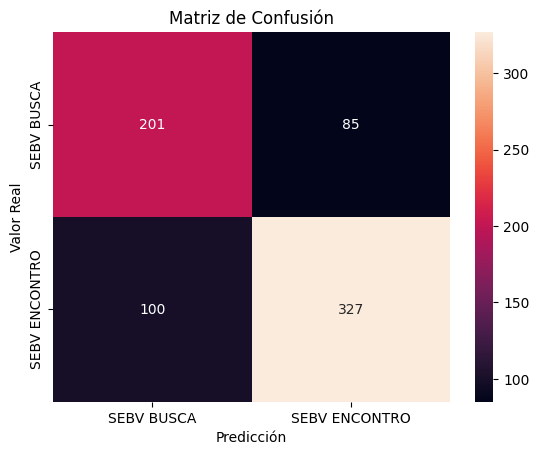

In [33]:
# Para Random Forest
y_pred_val = modelo_rf.predict(X_val)

# 1.
print("Classification Report (Validación):\n",
      classification_report(y_val, y_pred_val,
                            target_names=['SEBV BUSCA', 'SEBV ENCONTRO']))

# Matriz de confusión 1.
cf_matrix = confusion_matrix(y_val, y_pred_val)
sns.heatmap(cf_matrix, fmt='d', annot=True,
            xticklabels=['SEBV BUSCA', 'SEBV ENCONTRO'],
            yticklabels=['SEBV BUSCA', 'SEBV ENCONTRO'])
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Matriz de Confusión")
plt.show()

Referencia:
1. Arévalo F, Samsó J. (16 de marzo 2026). *Ayudantía 1: Intro a ML, uso de pandas, numpy, y sklearn*. Archivo .ipynb. Recuperado de Canvas uc.

In [34]:
# Hacemos feature importance del Random Forest
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importancias.head(10)) # top 10


EncontradoOtraVia                   0.338399
sin_valor_comercial_veh             0.103649
tve_desc_CAMIONETA                  0.099107
mar_freq                            0.092198
sin_ano_vechiculo                   0.066621
tve_desc_STATION WAGON              0.059973
dias_hasta_denuncia                 0.047686
reg_descripcion_region_asegurado    0.023507
ase_abreviatura                     0.016686
sin_hora_cat                        0.015393
dtype: float64


Text(0, 0.5, 'Importancia')

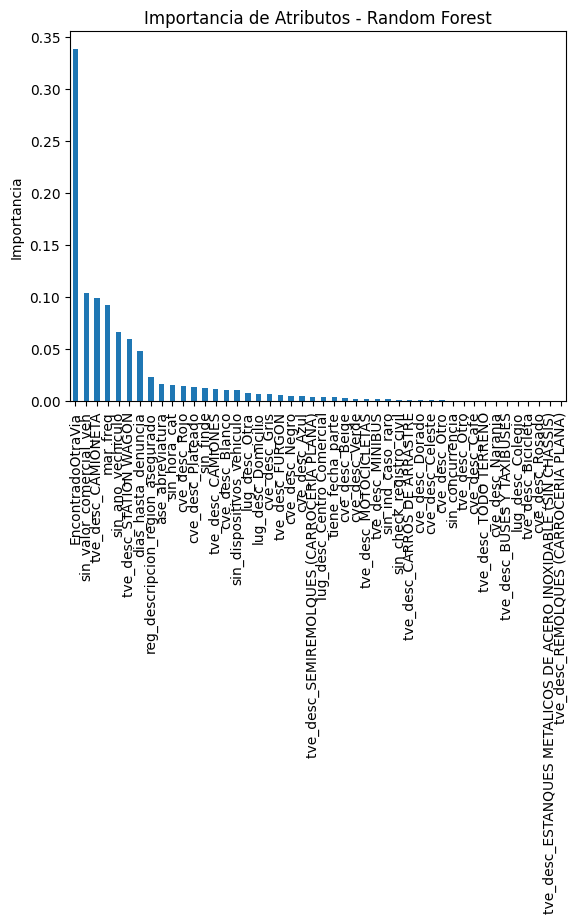

In [35]:
# Graficamos para ver detalladamente la importancia de las features
fig, ax = plt.subplots()
importancias.plot.bar(ax=ax)
ax.set_title("Importancia de Atributos - Random Forest")
ax.set_ylabel("Importancia")

Referencia:
Scikit-learn. (s.f.). Feature importance evaluation with a forest of trees. https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

La matriz muestra que de los 286 vehículos realmente en estado BUSCA, el modelo clasificó correctamente 201 (TN) y cometió 85 falsos positivos (predijo ENCONTRO cuando el auto aún no apareció). De los 427 vehículos realmente encontrados, clasificó correctamente 327 (TP) y cometió 100 falsos negativos (predijo BUSCA cuando el auto sí fue encontrado).

Por otro lado, viendo la importancia de atributos del random forest la variabe más importante por lejos es EncontradoOtraVia con un valor de 0.338399, muy superior al siguiente que es sin_valor_comercial_veh que es aproximadamente 0.10. Resulta interesante que features que uno pensaría que no ofrecen tanta información, si son consideradas relevantes como lo son tve_desc_STATION WAGON o tve_desc_CAMIONES

**Análisis crítico de errores**:

A partir de la matriz de confusión del mejor modelo, los errores más frecuentes son los falsos negativos (100 casos): el modelo predice BUSCA cuando el vehículo realmente fue encontrado. Esto tiene una consecuencia práctica importante: el SEBV podría reducir esfuerzos de búsqueda en casos que sí tienen posibilidades reales de resolverse.

Los falsos positivos (85 casos) representan el error opuesto: el modelo predice ENCONTRO cuando el auto nunca aparece, generando expectativas falsas en el asegurado.
Estimo que el desbalanceo (60/40) hacia la variable SEBV ENCONTRO sesga las predicciones a esta misma. Además, la variable más importante (EncontradoOtraVia) genera una pregunta sobre su disponibilidad real al momento de predecir: si el vehículo aún no ha sido encontrado por ninguna vía, ese dato no existiría, lo que invalidaría la feature en producción.

Finalmente, creo que un modelo de IA no podría tomar decisiones tan importantes con estos tipos de datos ya que estos son registros históricos, uno nunca sabe si un vehículo que antes no fue encontrado, en un futuro sí pueda ser recuperado. Si en el pasado a lo mejor un tipo de vehículo fue tratado con menos atención o simplemente si un vehículo es extraño y no tiene muchos registros, el modelo no podría predecir bien el resultado de un proceso de búsqueda. Cualquier implementación de este tipo debe incluir a los seres humanos para no llegar a tomar decisiones que pueden muy fuertemente perjudicar, beneficiar o en general, afectar fuertemente las vidas de las personas.

## Uso de IA

### DCCoches

[1] La línea me la autocompletó gemini, pero igual le pedí ideas de cómo hacer el filtro de los datos de las horas, me dijo como usar datetime y después me citó la documentación necesaria.

[2] Se utilizó IA para preguntarle cómo ver que modelo era mejor en el modelo de clasificación.


*Prompt*: Me puedes decir con qué métrica medir cual modelo es mejor? (Le dí también contexto sobre qupe eran los modelos y qué querían predecir)


*Respuesta:* Depende de qué error te importa más evitar en tu problema. Hay tres escenarios:
Si ambos errores importan igual → usa F1
Es el caso más común y el más justificable para cualquier trabajo. Si hay desbalanceo en las variables de predicción, F1 es más honesta que accuracy.
Si lo más grave es predecir ENCONTRO cuando en realidad es BUSCA (le dices al asegurado "van a encontrar tu auto" y no es verdad → expectativa falsa) → prioriza Precision.
Si lo más grave es predecir BUSCA cuando en realidad es ENCONTRO (el SEBV deja de buscar un auto que sí podría recuperar → caso perdido evitable) → prioriza Recall.

[3] Usé mucha IA para el modelo SVM, no quería utilizar el modelo lineal de scikitlearn, pero nunca me convergía el modelo, le preguntaba cuanto era el tiempo estimado para que converja el modelo, qué cosas podía hacer para que convergiera más rápido, como variar el C, etc. Nunca me dió un código entero sino que me sugería cambios y yo los iba probando poco a poco en la tarea.